Install libraries

In [1]:
!pip -q install pymupdf transformers accelerate sentence-transformers faiss-cpu pandas matplotlib seaborn

Upload PDF & clean text

In [2]:
import fitz
import re
import json
from pathlib import Path
from google.colab import files

output_dir = Path("/content/nepal_imf_output")
output_dir.mkdir(exist_ok=True)

pdf_files = list(Path("/content").glob("*.pdf"))

if pdf_files:
    pdf_path = pdf_files[0]
else:
    uploaded = files.upload()
    pdf_path = Path("/content") / next(
        name for name in uploaded if name.lower().endswith(".pdf")
    )

def clean_text(text):
    text = text.replace("\u00a0", " ")
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)

    lines = []
    for line in text.splitlines():
        line = re.sub(r"[ \t]+", " ", line).strip()

        if not line:
            lines.append("")
            continue

        if re.fullmatch(r"\d{1,3}", line):
            continue

        if re.fullmatch(r"NEPAL|INTERNATIONAL MONETARY FUND", line, re.I):
            continue

        if "©International Monetary Fund. Not for Redistribution" in line:
            continue

        lines.append(line)

    text = "\n".join(lines)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

doc = fitz.open(pdf_path)

pages = []
for page_no, page in enumerate(doc, start=1):
    text = clean_text(page.get_text("text"))
    pages.append({"page": page_no, "text": text})

full_text = "\n\n".join(p["text"] for p in pages)

(output_dir / "nepal_cleaned_text.txt").write_text(
    full_text, encoding="utf-8"
)

with open(output_dir / "nepal_pages.json", "w") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("PDF pages:", len(doc))
print("Extracted characters:", len(full_text))
print("Pages containing text:", sum(bool(p["text"]) for p in pages))
print("\nSample extracted text:\n")
print(full_text[:700])

doc.close()

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving 1934-7685-002.2025.issue-285-en.pdf to 1934-7685-002.2025.issue-285-en.pdf
PDF pages: 125
Extracted characters: 325683
Pages containing text: 124

Sample extracted text:



© 2025 International Monetary Fund
IMF Country Report No. 25/285
SIXTH REVIEW UNDER THE EXTENDED CREDIT
FACILITY ARRANGEMENT; PRESS RELEASE; STAFF
REPORT; AND STATEMENT BY THE EXECUTIVE
DIRECTOR FOR NEPAL
In the context of the Sixth Review Under the Extended Credit Facility Arrangement, the
following documents have been released and are included in this package:

•
A Press Release including a statement by the Chair of the Executive Board.
•
The Staff Report prepared by a staff team of the IMF for the Executive Board’s
consideration on October 1, 2025 following discussions that ended on June 10, 2025,
with the officials of Nepal on economic developments and policies underpinning the
IMF arr


Tokem Aware Chunking

In [3]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-7B-Instruct"
)

chunk_size = 450
overlap = 50

chunks = []

for page in pages:
    if not page["text"]:
        continue

    tokens = tokenizer.encode(
        page["text"],
        add_special_tokens=False
    )

    start = 0

    while start < len(tokens):
        end = min(start + chunk_size, len(tokens))

        chunk_text = tokenizer.decode(
            tokens[start:end],
            skip_special_tokens=True
        )

        chunks.append({
            "chunk_id": len(chunks),
            "page": page["page"],
            "text": chunk_text,
            "token_count": end - start
        })

        if end == len(tokens):
            break

        start = end - overlap

with open(output_dir / "nepal_chunks.json", "w") as f:
    json.dump(chunks, f, indent=2, ensure_ascii=False)

print("Total chunks:", len(chunks))
print("Maximum tokens:", max(c["token_count"] for c in chunks))
print("Minimum tokens:", min(c["token_count"] for c in chunks))
print("Pages covered:", len(set(c["page"] for c in chunks)))
print("\nFirst chunk:\n")
print(chunks[0]["text"][:600])

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Total chunks: 273
Maximum tokens: 450
Minimum tokens: 22
Pages covered: 124

First chunk:

© 2025 International Monetary Fund
IMF Country Report No. 25/285
SIXTH REVIEW UNDER THE EXTENDED CREDIT
FACILITY ARRANGEMENT; PRESS RELEASE; STAFF
REPORT; AND STATEMENT BY THE EXECUTIVE
DIRECTOR FOR NEPAL
In the context of the Sixth Review Under the Extended Credit Facility Arrangement, the
following documents have been released and are included in this package:

•
A Press Release including a statement by the Chair of the Executive Board.
•
The Staff Report prepared by a staff team of the IMF for the Executive Board’s
consideration on October 1, 2025 following discussions that ended on June 10


In [4]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

GPU available: True
GPU: NVIDIA A100-SXM4-80GB
GPU memory (GB): 85.09


Load the Primary LLM

In [5]:
import torch
from transformers import AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-7B-Instruct"

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)

model.eval()

def ask_llm(prompt, max_tokens=250):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an economic research assistant analysing IMF reports. "
                "Use only the supplied source text. "
                "Do not invent statistics or policy conclusions. "
                "Distinguish historical findings from forecasts."
            )
        },
        {"role": "user", "content": prompt}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    if hasattr(inputs, "input_ids"):
        inputs = inputs["input_ids"]

    inputs = inputs.to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            input_ids=inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    response = outputs[0][inputs.shape[-1]:]

    return tokenizer.decode(
        response,
        skip_special_tokens=True
    ).strip()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/27.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

Identify the main IMF report sections

In [6]:
section_names = [
    "CONTEXT",
    "RECENT DEVELOPMENTS",
    "OUTLOOK AND RISKS",
    "PROGRAM PERFORMANCE",
    "Fiscal Policy",
    "Monetary and Financial Policy",
    "Enhancing Governance and Other Structural Reforms to Boost Growth",
    "PROGRAM MODALITIES",
    "STAFF APPRAISAL"
]

section_text = "\n".join(
    f"\n[PDF PAGE {p['page']}]\n{p['text']}"
    for p in pages if p["page"] >= 10
)

positions = []
cursor = 0

for name in section_names:
    pattern = re.compile(
        r"(?im)^[ \t]*" + re.escape(name) + r"[ \t]*$"
    )

    match = pattern.search(section_text, cursor)

    if match:
        positions.append((name, match.start()))
        cursor = match.end()
    else:
        print("Missing:", name)

end_match = re.search(
    r"(?im)^[ \t]*Figure 2\.\s*Nepal",
    section_text[positions[-1][1]:]
)

report_end = (
    positions[-1][1] + end_match.start()
    if end_match else len(section_text)
)

sections = {}

for i, (name, start) in enumerate(positions):
    end = (
        positions[i + 1][1]
        if i + 1 < len(positions)
        else report_end
    )
    sections[name] = section_text[start:end].strip()

with open(output_dir / "nepal_sections.json", "w") as f:
    json.dump(sections, f, indent=2, ensure_ascii=False)

print("Sections identified:", len(sections))

for name, content in sections.items():
    print(name, "-", len(content), "characters")

Sections identified: 9
CONTEXT - 964 characters
RECENT DEVELOPMENTS - 5265 characters
OUTLOOK AND RISKS - 4365 characters
PROGRAM PERFORMANCE - 2328 characters
Fiscal Policy - 9362 characters
Monetary and Financial Policy - 10911 characters
Enhancing Governance and Other Structural Reforms to Boost Growth - 4893 characters
PROGRAM MODALITIES - 6570 characters
STAFF APPRAISAL - 8551 characters


Generate section summaries and executive summary

In [7]:
def split_for_summary(text, limit=3500):
    ids = tokenizer.encode(text, add_special_tokens=False)
    return [
        tokenizer.decode(ids[i:i + limit], skip_special_tokens=True)
        for i in range(0, len(ids), limit)
    ]

def summarise_section(name, content):
    parts = split_for_summary(content)
    notes = []

    for part in parts:
        prompt = f"""
Summarise this extract from the Nepal IMF report.
Identify the main economic findings, numerical evidence,
financial risks and relevant policy recommendations.

Use only the provided extract.
Distinguish actual results from forecasts.
Keep the summary concise.

Section: {name}

Source:
{part}
"""
        notes.append(ask_llm(prompt, max_tokens=200))

    combined = "\n".join(notes)

    prompt = f"""
Create one factual summary of the IMF section '{name}'.

Requirements:
- Fewer than 100 words.
- Use only the notes supplied.
- Retain important financial findings and risks.
- Avoid unsupported claims.
- Do not include an introduction or heading.

Notes:
{combined}
"""
    return ask_llm(prompt, max_tokens=160)

section_summaries = {}

for name, content in sections.items():
    summary = summarise_section(name, content)
    section_summaries[name] = summary

    print(f"\n{name}")
    print(summary)

with open(output_dir / "nepal_section_summaries.json", "w") as f:
    json.dump(section_summaries, f, indent=2, ensure_ascii=False)

executive_prompt = f"""
Using the following summaries of Nepal's IMF report,
produce an executive summary with 5 to 7 bullet points.

Focus on:
- Economic growth and inflation
- Fiscal and monetary policy
- Financial sector stability
- National strengths and vulnerabilities
- IMF policy recommendations

Use only the supplied summaries.
Distinguish IMF forecasts from observed results.
Do not invent financial figures.

Section summaries:
{json.dumps(section_summaries, ensure_ascii=False)}
"""

executive_summary = ask_llm(
    executive_prompt,
    max_tokens=400
)

with open(output_dir / "nepal_executive_summary.json", "w") as f:
    json.dump(
        {"executive_summary": executive_summary},
        f,
        indent=2,
        ensure_ascii=False
    )

print("\nEXECUTIVE SUMMARY\n")
print(executive_summary)

print("\nSection summaries:", len(section_summaries))


CONTEXT
Nepal's goods exports, accounting for 3.2% of GDP in FY2023/24, are primarily directed towards India (two-thirds) and the U.S. (11%). The country remains relatively insulated from global trade and aid disruptions, but second-round effects from elevated global policy uncertainties should be monitored. Key financial risks include potential impacts on remittances and near-term uncertainty from the cancellation of U.S.-financed projects, particularly in social sectors.

RECENT DEVELOPMENTS
The economic recovery strengthened in FY2024/25, with real GDP growth increasing to 4.3% from 3.7% in FY2023/24, driven by industrial activity and hydropower expansion. Inflation peaked at 6.1% y/y in December 2024 but declined to 2.7% y/y in June 2025 due to improved supply and low Indian inflation. The current account balance is projected to reach 3.9% of GDP in FY2024/25.

OUTLOOK AND RISKS
Growth is projected to strengthen to 5.2% in FY2025/26, driven by domestic demand and capital spending.

Excutive summary

In [8]:
fiscal_prompt = f"""
Summarise Nepal's fiscal policy in fewer than 100 words.

Clearly distinguish government budget targets from
IMF staff projections for FY2025/26.

Use only the supplied source. Do not invent figures.

Source:
{sections["Fiscal Policy"][:14000]}
"""

section_summaries["Fiscal Policy"] = ask_llm(
    fiscal_prompt, max_tokens=180
)

# Regenerate a concise executive summary
executive_prompt = f"""
Prepare an executive summary of Nepal's IMF report.

Write exactly five concise bullet points:
1. Economic growth and inflation
2. Fiscal and monetary policy
3. Financial sector stability
4. Economic strengths and vulnerabilities
5. IMF policy recommendations

Requirements:
- Maximum 220 words in total.
- Complete every bullet point.
- Use only the supplied summaries.
- Distinguish forecasts from actual results.
- Distinguish government budget targets from IMF forecasts.
- Do not invent statistics.

Source summaries:
{json.dumps(section_summaries, ensure_ascii=False)}
"""

executive_summary = ask_llm(
    executive_prompt, max_tokens=650
)

with open(output_dir / "nepal_section_summaries.json", "w") as f:
    json.dump(section_summaries, f, indent=2, ensure_ascii=False)

with open(output_dir / "nepal_executive_summary.json", "w") as f:
    json.dump(
        {"executive_summary": executive_summary},
        f, indent=2, ensure_ascii=False
    )

print("CORRECTED FISCAL SUMMARY\n")
print(section_summaries["Fiscal Policy"])

print("\nEXECUTIVE SUMMARY\n")
print(executive_summary)

print("\nSections:", len(section_summaries))
print("Maximum section words:",
      max(len(s.split()) for s in section_summaries.values()))

CORRECTED FISCAL SUMMARY

Nepal's FY2025/26 budget aims for a primary deficit of 1.6% of GDP, slightly below the IMF's projection of 2.0%. The budget targets a tax revenue increase to 19.5% of GDP and capital expenditure to 6% of GDP, focusing on structural reforms like allowing outward investment and increasing spending on public-private partnerships. The IMF projects a higher deficit due to lower tax revenue and capital expenditure forecasts. Public debt is expected to peak at 49.5% of GDP and decline thereafter, supported by fiscal consolidation.

EXECUTIVE SUMMARY

- Economic growth and inflation: Real GDP growth strengthened to 4.3% in FY2024/25 from 3.7% in FY2023/24, with inflation peaking at 6.1% y/y in December 2024 and declining to 2.7% y/y in June 2025. Growth is projected to further strengthen to 5.2% in FY2025/26, while inflation is expected to reach around 5%.

- Fiscal and monetary policy: The government aims for a primary deficit of 1.6% of GDP in FY2025/26, slightly be

Evidence for six financial indicators

In [9]:
indicator_terms = {
    "gdp_growth_forecast_pct": [
        "real gdp", "growth is projected", "growth forecast"
    ],
    "headline_inflation_rate_pct": [
        "headline cpi", "headline inflation", "inflation is projected"
    ],
    "central_bank_policy_rate_pct": [
        "policy rate", "interest rate corridor"
    ],
    "non_performing_loan_ratio": [
        "non-performing loans", "npls", "npl ratio"
    ],
    "unemployment_rate_pct": [
        "unemployment rate", "unemployment"
    ],
    "tier_1_capital_ratio": [
        "tier 1", "tier-1", "core capital"
    ]
}

def find_evidence(terms, max_pages=3):
    matches = []

    for page in pages:
        text = page["text"]
        lowered = text.lower()

        score = sum(
            lowered.count(term.lower())
            for term in terms
        )

        if score == 0:
            continue

        snippets = []

        for term in terms:
            for match in list(re.finditer(
                re.escape(term), text, re.IGNORECASE
            ))[:3]:
                start = max(0, match.start() - 450)
                end = min(len(text), match.end() + 650)
                snippets.append(text[start:end])

        matches.append({
            "page": page["page"],
            "score": score,
            "evidence": "\n---\n".join(snippets[:5])
        })

    return sorted(
        matches,
        key=lambda x: x["score"],
        reverse=True
    )[:max_pages]

indicator_evidence = {
    name: find_evidence(terms)
    for name, terms in indicator_terms.items()
}

with open(output_dir / "nepal_indicator_evidence.json", "w") as f:
    json.dump(indicator_evidence, f, indent=2, ensure_ascii=False)

for name, evidence in indicator_evidence.items():
    print(name, ":", [e["page"] for e in evidence])

gdp_growth_forecast_pct : [114, 115, 95]
headline_inflation_rate_pct : [5, 34, 13]
central_bank_policy_rate_pct : [7, 18, 26]
non_performing_loan_ratio : [54, 19, 56]
unemployment_rate_pct : []
tier_1_capital_ratio : [40, 11]


Extract financial indicators

In [10]:
def extract_indicator(name, evidence):
    if not evidence:
        return {
            "value": None,
            "period": None,
            "source_page": None,
            "evidence": None,
            "status": "missing_unverified"
        }

    source = "\n\n".join(
        f"PDF PAGE {e['page']}:\n{e['evidence']}"
        for e in evidence
    )

    prompt = f"""
Extract this financial indicator from the Nepal IMF report:

{name}

Rules:
- Return one numeric percentage value, not a fraction.
- For GDP growth use the IMF FY2025/26 forecast.
- For headline inflation use FY2025/26 projected
  period-average headline CPI.
- For interest rates use the explicitly named central
  bank policy rate, not the bank rate or SDF rate.
- For NPLs use the latest clearly dated reported ratio.
- For unemployment use a clearly reported unemployment rate.
- For Tier 1 capital use a reported Tier 1 ratio, not
  an unrelated capital measure.
- Never substitute a different indicator.
- Never invent unavailable values.
- If the evidence is insufficient, use null.
- Return valid JSON only, without markdown.

Required JSON:
{{
  "value": null,
  "period": null,
  "source_page": null,
  "evidence": null
}}

Source:
{source}
"""

    response = ask_llm(prompt, max_tokens=300)

    try:
        match = re.search(r"\{.*\}", response, re.S)
        result = json.loads(match.group()) if match else {}

        value = result.get("value")

        if isinstance(value, str):
            value = float(value.replace("%", "").replace(",", ""))

        if isinstance(value, bool) or not isinstance(
            value, (int, float)
        ):
            value = None

        page = result.get("source_page")
        try:
            page = int(page)
        except (ValueError, TypeError):
            page = None

        valid_pages = [e["page"] for e in evidence]

        if page not in valid_pages:
            page = None

        return {
            "value": value,
            "period": result.get("period"),
            "source_page": page,
            "evidence": result.get("evidence"),
            "status": (
                "pending_source_verification"
                if value is not None and page is not None
                else "missing_unverified"
                if value is None
                else "needs_source_review"
            )
        }

    except (ValueError, TypeError, AttributeError):
        return {
            "value": None,
            "period": None,
            "source_page": None,
            "evidence": None,
            "status": "parsing_failed"
        }


financial_data = {"country_name": "Nepal"}

for name, evidence in indicator_evidence.items():
    financial_data[name] = extract_indicator(name, evidence)

with open(output_dir / "nepal_financial_data.json", "w") as f:
    json.dump(financial_data, f, indent=2, ensure_ascii=False)

print("FINANCIAL EXTRACTION RESULTS\n")

for name, result in financial_data.items():
    if name == "country_name":
        continue

    print(
        name,
        "| Value:", result["value"],
        "| Period:", result["period"],
        "| PDF page:", result["source_page"],
        "| Status:", result["status"]
    )

FINANCIAL EXTRACTION RESULTS

gdp_growth_forecast_pct | Value: 9.8 | Period: FY2025/26 | PDF page: 114 | Status: pending_source_verification
headline_inflation_rate_pct | Value: 4.3 | Period: FY2025/26 | PDF page: 13 | Status: pending_source_verification
central_bank_policy_rate_pct | Value: 4.5 | Period: FY2025/26 | PDF page: 18 | Status: pending_source_verification
non_performing_loan_ratio | Value: 5.3 | Period: July 2022 to April 2025 | PDF page: 54 | Status: pending_source_verification
unemployment_rate_pct | Value: None | Period: None | PDF page: None | Status: missing_unverified
tier_1_capital_ratio | Value: 9.59 | Period: 2024/25 Q3 | PDF page: 40 | Status: pending_source_verification


verified financial JSON

In [11]:
import re
import json

def get_table_value(page_number, row_name, column_index, total_columns):
    text = pages[page_number - 1]["text"]

    lines = [line.strip() for line in text.splitlines() if line.strip()]

    for i, line in enumerate(lines):
        if line.lower() == row_name.lower():
            values = []

            for next_line in lines[i + 1:i + total_columns + 1]:
                if re.fullmatch(r"-?\d+(?:\.\d+)?", next_line):
                    values.append(float(next_line))

            if len(values) == total_columns:
                return values[column_index]

    raise ValueError(f"Could not verify {row_name} on PDF page {page_number}")


# Verify values against IMF source tables
gdp = get_table_value(5, "Real GDP", 4, 9)
inflation = get_table_value(5, "Headline CPI (period average)", 4, 9)

npl = get_table_value(40, "NPLs to total gross loans", 4, 5)
tier1 = get_table_value(
    40, "Tier 1 capital to risk weighted assets", 4, 5
)

# Extract policy rate from the monetary policy discussion
policy_text = re.sub(r"\s+", " ", pages[17]["text"])

policy_match = re.search(
    r'policy rate.{0,120}?to\s+(\d+(?:\.\d+)?)\s+percent',
    policy_text,
    re.IGNORECASE
)

policy_rate = float(policy_match.group(1)) if policy_match else None


def verified_record(value, period, page, evidence):
    return {
        "value": value,
        "period": period,
        "source_page": page,
        "evidence": evidence,
        "status": "source_verified" if value is not None else "missing_unverified"
    }


financial_data = {
    "country_name": "Nepal",

    "gdp_growth_forecast_pct": verified_record(
        gdp, "FY2025/26", 5,
        "Real GDP growth projection"
    ),

    "headline_inflation_rate_pct": verified_record(
        inflation, "FY2025/26", 5,
        "Headline CPI period-average projection"
    ),

    "central_bank_policy_rate_pct": verified_record(
        policy_rate, "FY2025/26", 18,
        "Nepal Rastra Bank policy rate"
    ),

    "non_performing_loan_ratio": verified_record(
        npl, "FY2024/25 Q3", 40,
        "NPLs to total gross loans"
    ),

    "unemployment_rate_pct": verified_record(
        None, None, None,
        "Unemployment rate not yet verified"
    ),

    "tier_1_capital_ratio": verified_record(
        tier1, "FY2024/25 Q3", 40,
        "Tier 1 capital to risk weighted assets"
    )
}

with open(output_dir / "nepal_financial_data.json", "w") as f:
    json.dump(financial_data, f, indent=2)

print("SOURCE-VERIFIED FINANCIAL DATA\n")

for name, result in financial_data.items():
    if name != "country_name":
        print(
            name, "|", result["value"],
            "| Page:", result["source_page"],
            "|", result["status"]
        )

SOURCE-VERIFIED FINANCIAL DATA

gdp_growth_forecast_pct | 5.2 | Page: 5 | source_verified
headline_inflation_rate_pct | 4.3 | Page: 5 | source_verified
central_bank_policy_rate_pct | 4.5 | Page: 18 | source_verified
non_performing_loan_ratio | 5.24 | Page: 40 | source_verified
unemployment_rate_pct | None | Page: None | missing_unverified
tier_1_capital_ratio | 9.59 | Page: 40 | source_verified


Seven Financial Themes

In [12]:
import pandas as pd

financial_themes = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bheadline cpi\b", r"\bprice stability\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bcredit growth\b",
        r"\blending rates?\b", r"\bmonetary policy\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\breal estate\b",
        r"\bproperty prices?\b", r"\bconstruction sector\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbank capital\b", r"\bcapital adequacy\b",
        r"\bliquidity\b", r"\btier 1\b",
        r"\bcapital buffers?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bgovernment debt\b",
        r"\bdebt sustainability\b", r"\bdebt distress\b"
    ],
    "Labor Market Dynamics": [
        r"\bemployment\b", r"\bunemployment\b",
        r"\blabor force\b", r"\blabour force\b",
        r"\bemigration\b", r"\bjob opportunities\b"
    ],
    "Systemic Financial Risk": [
        r"\bfinancial stability\b",
        r"\bfinancial sector vulnerabilities\b",
        r"\bnon.performing loans?\b",
        r"\bnpls?\b", r"\bsystemic risk\b",
        r"\bfinancial risks?\b"
    ]
}

# Count matches across the report
theme_results = []

for theme, patterns in financial_themes.items():
    count = sum(
        len(re.findall(pattern, full_text, flags=re.IGNORECASE))
        for pattern in patterns
    )

    theme_results.append({
        "Theme": theme,
        "Count": count
    })

theme_df = pd.DataFrame(theme_results)

total = theme_df["Count"].sum()

theme_df["Percentage"] = (
    theme_df["Count"] / total * 100
).round(2) if total else 0.0

theme_df = theme_df.sort_values(
    "Count", ascending=False
).reset_index(drop=True)

theme_df.to_csv(
    output_dir / "nepal_theme_distribution.csv",
    index=False
)

theme_df.to_json(
    output_dir / "nepal_theme_distribution.json",
    orient="records",
    indent=2
)

print("NEPAL IMF — FINANCIAL THEME DISTRIBUTION\n")
print(theme_df.to_string(index=False))

print("\nTotal theme matches:", total)
print("Themes analysed:", len(theme_df))
print("Total percentage:", round(theme_df["Percentage"].sum(), 2))

NEPAL IMF — FINANCIAL THEME DISTRIBUTION

                      Theme  Count  Percentage
             Sovereign Debt     93       25.69
    Systemic Financial Risk     91       25.14
    Interest Rates & Credit     77       21.27
         Inflation & Prices     40       11.05
Banking Capital & Liquidity     31        8.56
      Housing & Real Estate     17        4.70
      Labor Market Dynamics     13        3.59

Total theme matches: 362
Themes analysed: 7
Total percentage: 100.0


Economic Strengths and Vulnerabilities

In [13]:
# Use the source-grounded section summaries
risk_source = "\n\n".join(
    f"{name}:\n{summary}"
    for name, summary in section_summaries.items()
)

risk_prompt = f"""
Analyse the following Nepal IMF report summaries.

Identify:
1. Exactly 6 economic strengths or growth drivers.
2. Exactly 6 economic vulnerabilities or challenges.

Requirements:
- Use only the supplied IMF summaries.
- Each item must be a short, specific statement.
- Include financial stability, growth, fiscal and structural issues.
- Do not invent facts or statistics.
- Avoid duplicates.
- Return valid JSON only.

Required JSON format:
{{
  "strengths": [
    "Strength 1",
    "Strength 2"
  ],
  "vulnerabilities": [
    "Vulnerability 1",
    "Vulnerability 2"
  ]
}}

IMF source summaries:
{risk_source}
"""

response = ask_llm(risk_prompt, max_tokens=700)

try:
    match = re.search(r"\{.*\}", response, re.S)

    if not match:
        raise ValueError("No JSON object found")

    qualitative_data = json.loads(match.group())

    for key in ["strengths", "vulnerabilities"]:
        items = qualitative_data.get(key, [])

        if not isinstance(items, list) or len(items) != 6:
            raise ValueError(f"{key} must contain exactly 6 items")

        if not all(isinstance(item, str) and item.strip() for item in items):
            raise ValueError(f"Invalid entries in {key}")

    with open(output_dir / "nepal_qualitative_insights.json", "w") as f:
        json.dump(qualitative_data, f, indent=2, ensure_ascii=False)

    print("NEPAL — ECONOMIC STRENGTHS\n")
    for i, item in enumerate(qualitative_data["strengths"], 1):
        print(f"{i}. {item}")

    print("\nNEPAL — ECONOMIC VULNERABILITIES\n")
    for i, item in enumerate(qualitative_data["vulnerabilities"], 1):
        print(f"{i}. {item}")

    print("\nQualitative insights saved successfully.")

except (ValueError, json.JSONDecodeError) as error:
    print("Validation failed:", error)
    print("Raw model output:\n", response)

NEPAL — ECONOMIC STRENGTHS

1. Nepal's economic recovery strengthened with real GDP growth increasing to 4.3% in FY2024/25.
2. Inflation declined from 6.1% y/y in December 2024 to 2.7% y/y in June 2025.
3. The current account balance is projected to reach 3.9% of GDP in FY2024/25.
4. The program performance has been broadly adequate, meeting net international reserves, primary deficit, and tax revenue targets.
5. Significant progress has been made on draft NRB Act amendments and the Investment Facilitation Bill.
6. The government has resolved three problematic SACCOs, returning NPR 3 billion to depositors.

NEPAL — ECONOMIC VULNERABILITIES

1. Second-round effects from elevated global policy uncertainties should be monitored.
2. Remittance growth will moderate, which could impact the economy.
3. Imports are expected to rise, gradually reducing foreign exchange reserves.
4. Key structural reforms, such as the LPR of the 10 largest banks and amending the NRB Act, faced delays.
5. NPL rec

Extract four economic trend series

In [14]:
import pandas as pd
import json

years = [
    "2021/22", "2022/23", "2023/24",
    "2024/25", "2025/26", "2026/27",
    "2027/28", "2028/29", "2029/30"
]

trend_indicators = {
    "Real GDP Growth": ("Real GDP", "% annual change"),
    "Headline Inflation": ("Headline CPI (period average)", "% annual change"),
    "Private Sector Credit Growth": ("Private sector credit", "% annual change"),
    "Public Debt": ("Public debt (in percent of GDP)", "% of GDP")
}

trend_data = {"Fiscal Year": years}

for name, (row_name, unit) in trend_indicators.items():
    trend_data[name] = [
        get_table_value(5, row_name, i, len(years))
        for i in range(len(years))
    ]

trend_df = pd.DataFrame(trend_data)

# Convert wide-format data into long format
trend_long = pd.melt(
    trend_df,
    id_vars="Fiscal Year",
    var_name="Indicator",
    value_name="Value"
)

trend_long["Unit"] = trend_long["Indicator"].map(
    {name: unit for name, (_, unit) in trend_indicators.items()}
)

# Distinguish historical estimates from forecasts
trend_long["Type"] = trend_long["Fiscal Year"].apply(
    lambda year: "Projection"
    if int(year[:4]) >= 2025 else "Historical/Estimate"
)

trend_df.to_csv(
    output_dir / "nepal_economic_trends.csv",
    index=False
)

trend_long.to_csv(
    output_dir / "nepal_economic_trends_long.csv",
    index=False
)

with open(output_dir / "nepal_economic_trends.json", "w") as f:
    json.dump(
        trend_long.to_dict(orient="records"),
        f,
        indent=2
    )

print("NEPAL — ECONOMIC TREND DATA\n")
print(trend_df.to_string(index=False))

print("\nTrend series:", len(trend_indicators))
print("Fiscal years:", len(years))
print("Long-format rows:", len(trend_long))
print("Missing values:", trend_long["Value"].isna().sum())

NEPAL — ECONOMIC TREND DATA

Fiscal Year  Real GDP Growth  Headline Inflation  Private Sector Credit Growth  Public Debt
    2021/22              5.6                 6.4                          13.3         42.7
    2022/23              2.0                 7.7                           4.6         47.0
    2023/24              3.7                 5.4                           6.1         48.3
    2024/25              4.3                 4.2                           8.2         49.4
    2025/26              5.2                 4.3                           8.7         49.5
    2026/27              5.0                 5.0                           9.1         49.3
    2027/28              5.0                 5.0                           9.4         48.9
    2028/29              5.0                 5.0                           9.8         48.4
    2029/30              5.0                 5.0                          10.1         48.0

Trend series: 4
Fiscal years: 9
Long-format rows: 

Build and cache FAISS embeddings

In [15]:
import faiss
import numpy as np
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda"
)

index_path = output_dir / "nepal_faiss.index"
embeddings_path = output_dir / "nepal_embeddings.npy"

texts = [chunk["text"] for chunk in chunks]

if index_path.exists() and embeddings_path.exists():
    index = faiss.read_index(str(index_path))
    embeddings = np.load(embeddings_path)

    if index.ntotal != len(texts) or embeddings.shape[0] != len(texts):
        raise ValueError("Cached index does not match the current chunks")

    print("Loaded cached FAISS index.")

else:
    embeddings = embedding_model.encode(
        texts,
        batch_size=32,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=True
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    faiss.write_index(index, str(index_path))
    np.save(embeddings_path, embeddings)

    print("New FAISS index created and cached.")

print("Indexed documents:", index.ntotal)
print("Embedding dimensions:", index.d)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/9 [00:00<?, ?it/s]

New FAISS index created and cached.
Indexed documents: 273
Embedding dimensions: 384


RAG retrieval and grounded answers

In [16]:
def retrieve_context(question, top_k=4):
    query_vector = embedding_model.encode(
        [question],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    scores, indices = index.search(query_vector, top_k)

    results = []

    for score, idx in zip(scores[0], indices[0]):
        if idx < 0:
            continue

        chunk = chunks[int(idx)]

        results.append({
            "page": chunk["page"],
            "chunk_id": chunk["chunk_id"],
            "score": float(score),
            "text": chunk["text"]
        })

    return results


def ask_rag(question):
    retrieved = retrieve_context(question)

    context = "\n\n".join(
        f"[PDF Page {r['page']}, Chunk {r['chunk_id']}]\n{r['text']}"
        for r in retrieved
    )

    prompt = f"""
Answer the question using only the retrieved IMF report text.

Rules:
- Do not invent facts or statistics.
- Mention supporting PDF page numbers.
- If evidence is insufficient, state that clearly.
- Distinguish actual results from projections.
- Keep the answer under 150 words.

Question:
{question}

Retrieved IMF evidence:
{context}
"""

    answer = ask_llm(prompt, max_tokens=250)

    return {
        "question": question,
        "answer": answer,
        "retrieved_pages": [r["page"] for r in retrieved],
        "retrieval_scores": [round(r["score"], 4) for r in retrieved]
    }

Test RAG with four IMF questions

In [17]:
rag_questions = [
    "What are the main financial sector vulnerabilities in Nepal?",
    "What does the IMF recommend for resolving non-performing loans?",
    "How is Nepal's monetary policy supporting economic recovery?",
    "What risks could affect Nepal's medium-term economic growth?"
]

rag_results = []

for question in rag_questions:
    result = ask_rag(question)
    rag_results.append(result)

    print("\nQUESTION:", question)
    print("ANSWER:", result["answer"])
    print("RETRIEVED PAGES:", result["retrieved_pages"])

with open(output_dir / "nepal_rag_audit.json", "w") as f:
    json.dump(rag_results, f, indent=2, ensure_ascii=False)

print("\nRAG audit saved.")
print("Questions evaluated:", len(rag_results))


QUESTION: What are the main financial sector vulnerabilities in Nepal?
ANSWER: The main financial sector vulnerabilities in Nepal, as per the IMF report, include rising non-performing loans (NPLs), weaker capitalization, and stagnating credit to the private sector, particularly within the savings and credit cooperative (SACCO) sector. These issues warrant continued monitoring. (Page 91, Chunk 191)
RETRIEVED PAGES: [91, 34, 5, 4]

QUESTION: What does the IMF recommend for resolving non-performing loans?
ANSWER: The IMF recommends that banks with significant levels of non-performing loans (NPLs) and those that are systemically important participate in Asset Management Company (AMC) programs. Eligible NPLs and distressed assets should be clearly identified and transferred with accurate valuation and fair transfer pricing to ensure transparency and minimize moral hazard. The AMC should aim to recover the price paid for transferred assets, including operational and financial costs. Larger,

Load the evaluator model

In [18]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import json
import re

judge_name = "mistralai/Mistral-7B-Instruct-v0.3"

judge_tokenizer = AutoTokenizer.from_pretrained(judge_name)

judge_model = AutoModelForCausalLM.from_pretrained(
    judge_name,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    low_cpu_mem_usage=True
)

judge_model.eval()

def ask_judge(prompt, max_tokens=250):
    messages = [{"role": "user", "content": prompt}]

    inputs = judge_tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    if hasattr(inputs, "input_ids"):
        inputs = inputs["input_ids"]

    inputs = inputs.to(judge_model.device)

    with torch.inference_mode():
        outputs = judge_model.generate(
            input_ids=inputs,
            max_new_tokens=max_tokens,
            do_sample=False,
            pad_token_id=judge_tokenizer.eos_token_id
        )

    return judge_tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    ).strip()

print("Evaluator model loaded successfully!")
print("Primary model: Qwen2.5-7B-Instruct")
print("Evaluator model: Mistral-7B-Instruct-v0.3")

config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/141k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Evaluator model loaded successfully!
Primary model: Qwen2.5-7B-Instruct
Evaluator model: Mistral-7B-Instruct-v0.3


Evaluate section summaries, financial extraction and RAG

In [19]:
import pandas as pd

def evaluate_output(source, generated, task):
    prompt = f"""
You are an independent evaluator of an IMF report analysis.

Evaluate the generated output against the supplied source.

Score each criterion from 1 to 5:
1 = Very poor
2 = Poor
3 = Acceptable
4 = Good
5 = Excellent

Criteria:
- accuracy: Are factual claims supported by the source?
- completeness: Does the answer cover the important information?
- consistency: Are figures, dates and interpretations consistent?

Penalise hallucinations, incorrect figures, unsupported
recommendations and missing relevant information.

Return ONLY valid JSON:
{{
  "accuracy": 1,
  "completeness": 1,
  "consistency": 1,
  "reason": "Brief explanation"
}}

Task: {task}

SOURCE:
{source[:11000]}

GENERATED OUTPUT:
{generated[:3500]}
"""

    response = ask_judge(prompt, max_tokens=220)

    try:
        match = re.search(r"\{.*?\}", response, re.S)
        result = json.loads(match.group())

        scores = {}
        for key in ["accuracy", "completeness", "consistency"]:
            value = int(result[key])
            if not 1 <= value <= 5:
                raise ValueError("Score outside 1–5 range")
            scores[key] = value

        return {
            **scores,
            "reason": str(result.get("reason", "")),
            "status": "evaluated"
        }

    except (ValueError, TypeError, KeyError, AttributeError):
        return {
            "accuracy": None,
            "completeness": None,
            "consistency": None,
            "reason": response[:500],
            "status": "review_required"
        }


# Section summary evaluation
summary_evaluations = []

for name, summary in section_summaries.items():
    result = evaluate_output(
        sections[name],
        summary,
        "IMF section summarisation"
    )

    summary_evaluations.append({
        "section": name,
        **result
    })


# Financial indicator evaluation
financial_evaluations = []

for name, record in financial_data.items():
    if name == "country_name":
        continue

    original = extract_indicator(
        name,
        indicator_evidence[name]
    )

    evidence_text = "\n".join(
        f"PDF page {e['page']}: {e['evidence']}"
        for e in indicator_evidence[name]
    )

    result = evaluate_output(
        evidence_text,
        json.dumps(original),
        f"Financial indicator extraction: {name}"
    )

    financial_evaluations.append({
        "indicator": name,
        "original_value": original["value"],
        "verified_value": record["value"],
        **result
    })


# RAG evaluation
rag_evaluations = []

for item in rag_results:
    retrieved = retrieve_context(item["question"])

    source = "\n\n".join(
        f"PDF page {r['page']}:\n{r['text']}"
        for r in retrieved
    )

    result = evaluate_output(
        source,
        item["answer"],
        f"RAG question: {item['question']}"
    )

    rag_evaluations.append({
        "question": item["question"],
        **result
    })


# Save results
summary_eval_df = pd.DataFrame(summary_evaluations)
financial_eval_df = pd.DataFrame(financial_evaluations)
rag_eval_df = pd.DataFrame(rag_evaluations)

summary_eval_df.to_csv(
    output_dir / "nepal_summary_evaluation.csv",
    index=False
)

financial_eval_df.to_csv(
    output_dir / "nepal_financial_evaluation.csv",
    index=False
)

rag_eval_df.to_csv(
    output_dir / "nepal_rag_evaluation.csv",
    index=False
)

for title, df in [
    ("SUMMARISATION", summary_eval_df),
    ("FINANCIAL EXTRACTION", financial_eval_df),
    ("RAG", rag_eval_df)
]:
    print("\n", title)
    print(df[[
        "accuracy", "completeness", "consistency"
    ]].mean().round(2))

    print("Evaluated:",
          (df["status"] == "evaluated").sum(),
          "/", len(df))


 SUMMARISATION
accuracy        4.0
completeness    4.0
consistency     4.0
dtype: float64
Evaluated: 9 / 9

 FINANCIAL EXTRACTION
accuracy        4.33
completeness    4.33
consistency     4.33
dtype: float64
Evaluated: 6 / 6

 RAG
accuracy        4.25
completeness    4.25
consistency     4.25
dtype: float64
Evaluated: 4 / 4


Dashboard

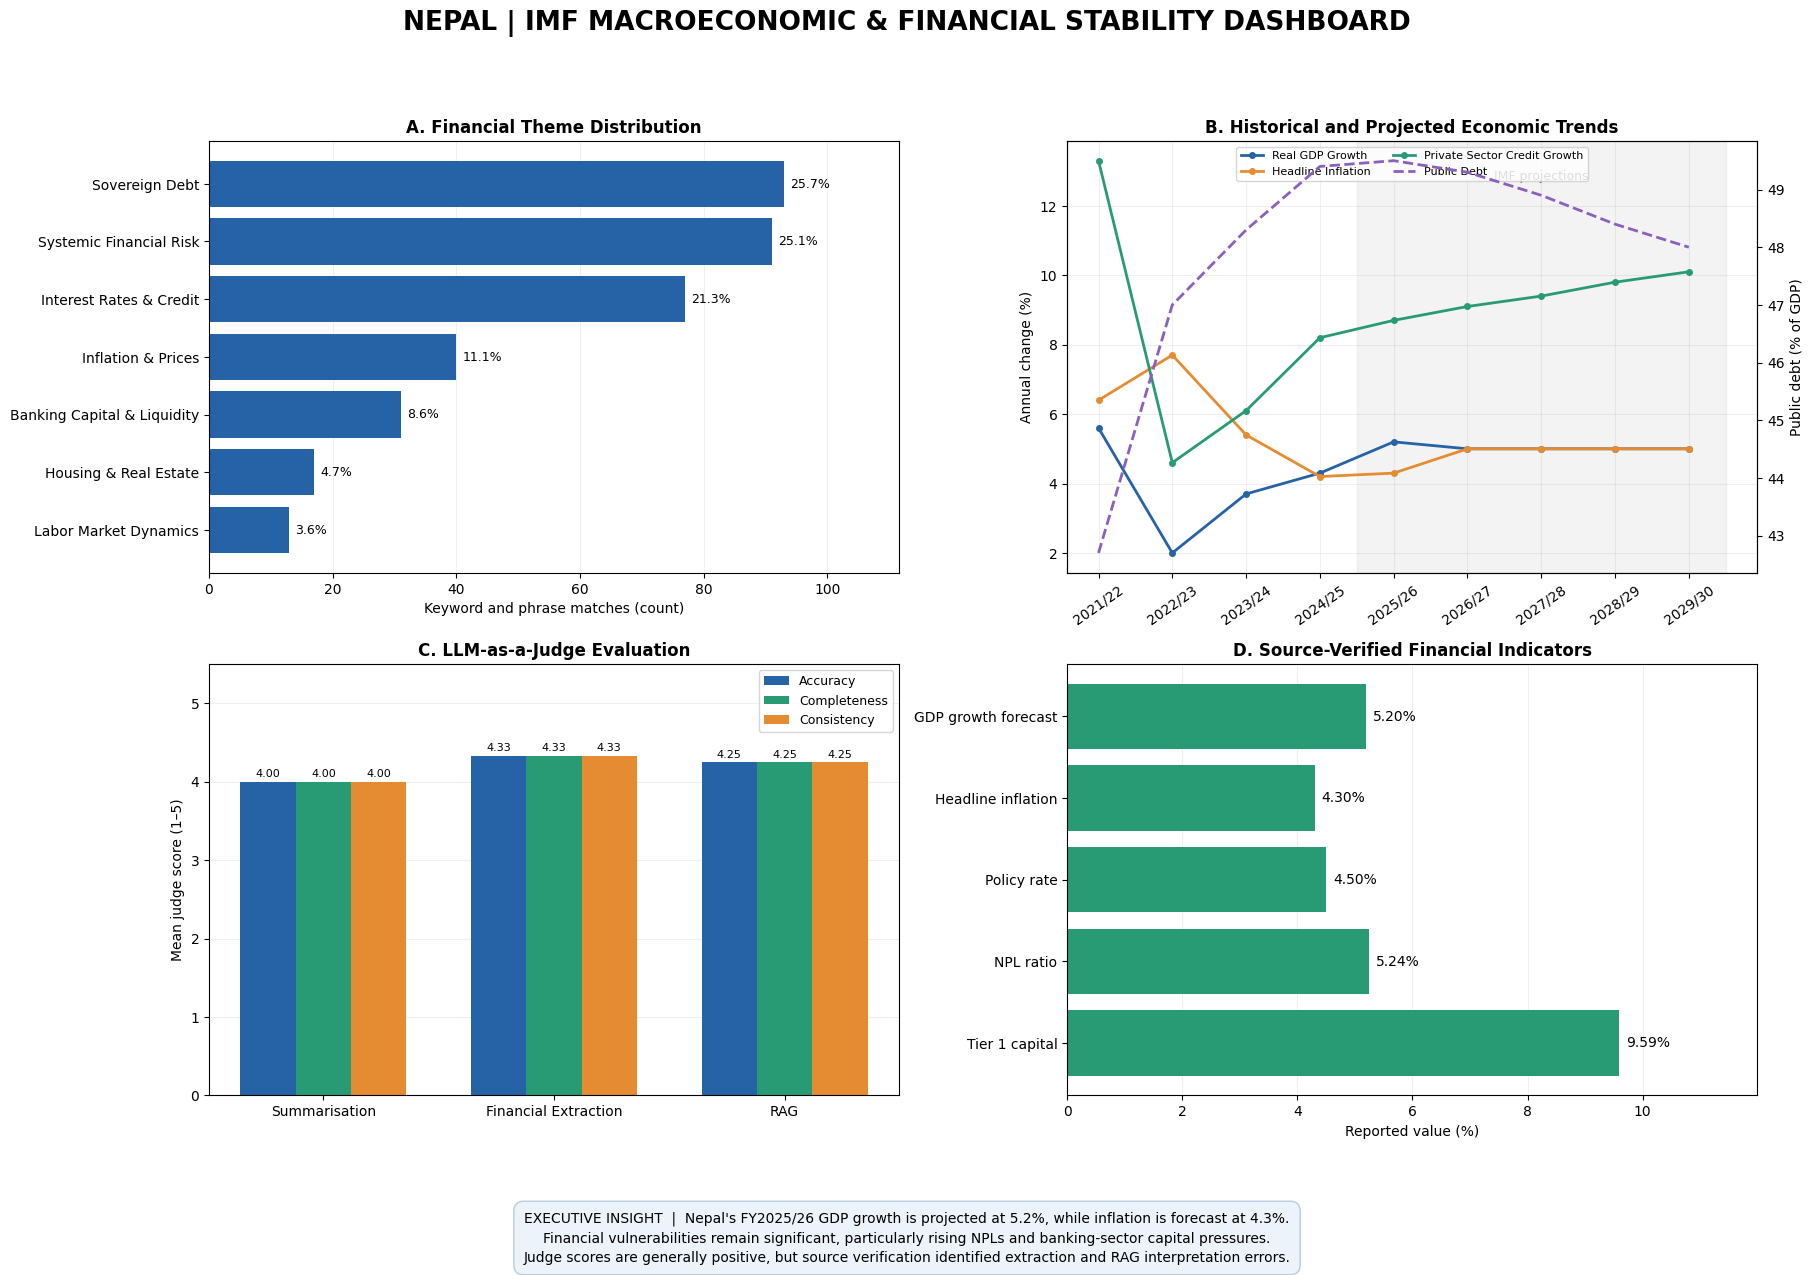

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Prepare evaluation scores
evaluation_data = pd.DataFrame({
    "Task": ["Summarisation", "Financial Extraction", "RAG"],
    "Accuracy": [
        summary_eval_df["accuracy"].mean(),
        financial_eval_df["accuracy"].mean(),
        rag_eval_df["accuracy"].mean()
    ],
    "Completeness": [
        summary_eval_df["completeness"].mean(),
        financial_eval_df["completeness"].mean(),
        rag_eval_df["completeness"].mean()
    ],
    "Consistency": [
        summary_eval_df["consistency"].mean(),
        financial_eval_df["consistency"].mean(),
        rag_eval_df["consistency"].mean()
    ]
})


evaluation_long = pd.melt(
    evaluation_data,
    id_vars="Task",
    var_name="Metric",
    value_name="Score"
)

evaluation_long.to_csv(
    output_dir / "nepal_evaluation_long.csv",
    index=False
)

indicator_labels = {
    "gdp_growth_forecast_pct": "GDP growth forecast",
    "headline_inflation_rate_pct": "Headline inflation",
    "central_bank_policy_rate_pct": "Policy rate",
    "non_performing_loan_ratio": "NPL ratio",
    "tier_1_capital_ratio": "Tier 1 capital"
}

indicator_rows = []

for key, label in indicator_labels.items():
    record = financial_data[key]

    if record["value"] is not None:
        indicator_rows.append({
            "Indicator": label,
            "Value": float(record["value"])
        })

indicator_df = pd.DataFrame(indicator_rows)

# Create the dashboard
fig, axes = plt.subplots(2, 2, figsize=(19, 13))
fig.patch.set_facecolor("white")

fig.suptitle(
    "NEPAL | IMF MACROECONOMIC & FINANCIAL STABILITY DASHBOARD",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

# Panel 1: Financial theme distribution
ax = axes[0, 0]

theme_plot = theme_df.sort_values("Count")

bars = ax.barh(
    theme_plot["Theme"],
    theme_plot["Count"],
    color="#2563A6"
)

for bar, pct in zip(bars, theme_plot["Percentage"]):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%",
        va="center",
        fontsize=9
    )

ax.set_title("A. Financial Theme Distribution", fontweight="bold")
ax.set_xlabel("Keyword and phrase matches (count)")
ax.set_xlim(0, theme_plot["Count"].max() * 1.20)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)


# Panel 2: Economic trends
ax = axes[0, 1]
x = np.arange(len(trend_df))

series = {
    "Real GDP Growth": "#2563A6",
    "Headline Inflation": "#E58C33",
    "Private Sector Credit Growth": "#289B75"
}

for name, color in series.items():
    ax.plot(
        x,
        trend_df[name],
        marker="o",
        linewidth=2,
        markersize=4,
        label=name,
        color=color
    )

# Secondary scale for public debt (% of GDP)
ax2 = ax.twinx()

ax2.plot(
    x,
    trend_df["Public Debt"],
    color="#8B5FBF",
    linestyle="--",
    linewidth=2,
    label="Public Debt"
)

ax.axvspan(3.5, 8.5, color="gray", alpha=0.09)
ax.text(
    6, ax.get_ylim()[1] * 0.92,
    "IMF projections",
    ha="center",
    fontsize=9,
    color="#555555"
)

ax.set_title("B. Historical and Projected Economic Trends",
             fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(trend_df["Fiscal Year"], rotation=35)
ax.set_ylabel("Annual change (%)")
ax2.set_ylabel("Public debt (% of GDP)")
ax.grid(alpha=0.2)

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax.legend(
    lines1 + lines2,
    labels1 + labels2,
    fontsize=8,
    loc="upper center",
    ncol=2
)


# Panel 3: LLM evaluation
ax = axes[1, 0]

metrics = ["Accuracy", "Completeness", "Consistency"]
colors = ["#2563A6", "#289B75", "#E58C33"]
positions = np.arange(len(evaluation_data))
width = 0.24

for i, metric in enumerate(metrics):
    values = evaluation_data[metric]

    bars = ax.bar(
        positions + (i - 1) * width,
        values,
        width,
        label=metric,
        color=colors[i]
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.06,
            f"{bar.get_height():.2f}",
            ha="center",
            fontsize=8
        )

ax.set_title("C. LLM-as-a-Judge Evaluation", fontweight="bold")
ax.set_xticks(positions)
ax.set_xticklabels(evaluation_data["Task"])
ax.set_ylabel("Mean judge score (1–5)")
ax.set_ylim(0, 5.5)
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)


# Panel 4: Source-verified indicators
ax = axes[1, 1]

bars = ax.barh(
    indicator_df["Indicator"],
    indicator_df["Value"],
    color="#289B75"
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center",
        fontsize=10
    )

ax.invert_yaxis()
ax.set_title("D. Source-Verified Financial Indicators",
             fontweight="bold")
ax.set_xlabel("Reported value (%)")
ax.set_xlim(0, indicator_df["Value"].max() * 1.25)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)


# Executive insight overlay
insight = (
    "EXECUTIVE INSIGHT  |  Nepal's FY2025/26 GDP growth is projected at 5.2%, "
    "while inflation is forecast at 4.3%.\n"
    "Financial vulnerabilities remain significant, particularly rising NPLs "
    "and banking-sector capital pressures.\n"
    "Judge scores are generally positive, but source verification identified "
    "extraction and RAG interpretation errors."
)

fig.text(
    0.5, 0.035,
    insight,
    ha="center",
    va="center",
    fontsize=10,
    linespacing=1.5,
    bbox=dict(
        boxstyle="round,pad=0.7",
        facecolor="#EDF3FA",
        edgecolor="#B8CCDF"
    )
)

plt.tight_layout(rect=[0.02, 0.10, 0.98, 0.94])

dashboard_path = output_dir / "nepal_imf_dashboard.png"

plt.savefig(
    dashboard_path,
    dpi=320,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Final Validation check

In [21]:
import json
import pandas as pd
from pathlib import Path
from PIL import Image

required_files = [
    "nepal_cleaned_text.txt",
    "nepal_pages.json",
    "nepal_chunks.json",
    "nepal_sections.json",
    "nepal_section_summaries.json",
    "nepal_executive_summary.json",
    "nepal_indicator_evidence.json",
    "nepal_financial_data.json",
    "nepal_theme_distribution.json",
    "nepal_qualitative_insights.json",
    "nepal_economic_trends.csv",
    "nepal_economic_trends_long.csv",
    "nepal_faiss.index",
    "nepal_embeddings.npy",
    "nepal_rag_audit.json",
    "nepal_summary_evaluation.csv",
    "nepal_financial_evaluation.csv",
    "nepal_rag_evaluation.csv",
    "nepal_imf_dashboard.png"
]

checks = {}

checks["Required files"] = all(
    (output_dir / name).is_file()
    for name in required_files
)

checks["PDF pages"] = len(pages) == 125
checks["Token-aware chunks"] = (
    len(chunks) > 0 and
    all(0 < c["token_count"] <= 450 for c in chunks)
)

checks["Nine section summaries"] = (
    len(section_summaries) == 9 and
    all(len(s.split()) < 100 for s in section_summaries.values())
)

checks["Executive summary"] = (
    executive_summary.count("\n- ") +
    int(executive_summary.lstrip().startswith("- ")) == 5
)

required_indicators = [
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]

checks["Financial JSON schema"] = all(
    key in financial_data and
    isinstance(financial_data[key], dict) and
    "value" in financial_data[key]
    for key in required_indicators
)

checks["Five numeric indicators"] = sum(
    financial_data[key]["value"] is not None
    for key in required_indicators
) == 5

checks["Seven financial themes"] = len(theme_df) == 7

checks["Qualitative insights"] = (
    len(qualitative_data.get("strengths", [])) == 6 and
    len(qualitative_data.get("vulnerabilities", [])) == 6
)

checks["Four trend series"] = (
    trend_long["Indicator"].nunique() == 4 and
    len(trend_long) == 36
)

checks["FAISS embedding index"] = (
    index.ntotal == len(chunks) and
    index.d == 384
)

checks["Four RAG audits"] = len(rag_results) == 4

checks["Nine summary evaluations"] = (
    (summary_eval_df["status"] == "evaluated").sum() == 9
)

checks["Six financial evaluations"] = (
    (financial_eval_df["status"] == "evaluated").sum() == 6
)

checks["Four RAG evaluations"] = (
    (rag_eval_df["status"] == "evaluated").sum() == 4
)

dashboard_file = output_dir / "nepal_imf_dashboard.png"

if dashboard_file.exists():
    with Image.open(dashboard_file) as img:
        checks["High-resolution dashboard"] = (
            img.width >= 3000 and img.height >= 2000
        )
else:
    checks["High-resolution dashboard"] = False

print("FINAL PROJECT VALIDATION\n")

print("Required files:", len(required_files))
print("Files available:", sum(
    (output_dir / name).is_file()
    for name in required_files
))

print("\nVALIDATION RESULTS\n")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

passed = sum(checks.values())

print("\nFINAL RESULT")
print("Checks passed:", passed, "/", len(checks))
print("Status:", "PASS" if all(checks.values()) else "REVIEW REQUIRED")

FINAL PROJECT VALIDATION

Required files: 19
Files available: 19

VALIDATION RESULTS

Required files: PASS
PDF pages: PASS
Token-aware chunks: PASS
Nine section summaries: PASS
Executive summary: PASS
Financial JSON schema: PASS
Five numeric indicators: PASS
Seven financial themes: PASS
Qualitative insights: PASS
Four trend series: PASS
FAISS embedding index: PASS
Four RAG audits: PASS
Nine summary evaluations: PASS
Six financial evaluations: PASS
Four RAG evaluations: PASS
High-resolution dashboard: PASS

FINAL RESULT
Checks passed: 16 / 16
Status: PASS
